1)Problem statement  

This project understands how the students performance is affected by other variables such as gender , ethnicity,parental level of education ,Lunch and test preparation course


2) Data Collection 

dataset source- https://www.kaggle.com/datasets/spscientist/students-performance-in-exams
The data consist of 8 columns and 1000 rows


2.1 Import Data and required Packages
 Importing Pandas , Numpy, Matplotlib, Seaborn, and warings library.
 

In [19]:
import numpy as numpy
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [3]:
df= pd.read_csv('D:/mlProject/notebook/data/stud.csv')


In [4]:
df.head()
df.shape

(1000, 8)

In [5]:
df.isna().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [8]:
df.nunique()


gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

In [9]:
df.describe(include='all')

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
count,1000,1000,1000,1000,1000,1000.00000,1000.000000,1000.000000
unique,2,5,6,2,2,NaN,NaN,NaN
top,female,group C,some college,standard,none,NaN,NaN,NaN
freq,518,319,226,645,642,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,66.08900,69.169000,68.054000
std,NaN,NaN,NaN,NaN,NaN,15.16308,14.600192,15.195657
min,NaN,NaN,NaN,NaN,NaN,0.00000,17.000000,10.000000
25%,NaN,NaN,NaN,NaN,NaN,57.00000,59.000000,57.750000
50%,NaN,NaN,NaN,NaN,NaN,66.00000,70.000000,69.000000
75%,NaN,NaN,NaN,NaN,NaN,77.00000,79.000000,79.000000


In [10]:
print("categories in 'gender' variable:   ",end=" ")
print(df['gender'].unique())

print("categories in 'race/ethnicity' variable:   ",end=" ")
print(df['race/ethnicity'].unique())    

print("categories in 'parental level of education' variable:   ",end=" ")
print(df['parental level of education'].unique())

print("categories in 'lunch' variable:   ",end=" ")
print(df['lunch'].unique())

print("categories in 'test preparation course' variable:   ",end=" "
      )
print(df['test preparation course'].unique())


categories in 'gender' variable:    <StringArray>
['female', 'male']
Length: 2, dtype: str
categories in 'race/ethnicity' variable:    <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
categories in 'parental level of education' variable:    <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
categories in 'lunch' variable:    <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
categories in 'test preparation course' variable:    <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [11]:
numeric_features = [feature for feature in df.columns if df[feature].dtype != 'O']
categorical_features=[feature for feature in df.columns if df[feature].dtype=='O']
print('Numeric Features:',numeric_features)
print('Categorical Features:',categorical_features)

Numeric Features: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']
Categorical Features: []


In [12]:
df['total score']=df['math score']+df['reading score']+df['writing score']
df['average score']=df['total score']/3
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total score,average score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [16]:
reading_full=df[df['reading score']==100]['average score'].count()
writing_full=df[df['writing score']==100]['average score'].count()
math_full=df[df['math score']==100]['average score'].count()

print("Number of students who scored full marks in reading: ",reading_full)
print("Number of students who scored full marks in writing: ",writing_full) 
print("Number of students who scored full marks in math: ",math_full) 

Number of students who scored full marks in reading:  17
Number of students who scored full marks in writing:  14
Number of students who scored full marks in math:  7


In [17]:
reading_full=df[df['reading score']<=20]['average score'].count()
writing_full=df[df['writing score']<=20]['average score'].count()
math_full=df[df['math score']<=20]['average score'].count()

print("Number of students who scored full marks in reading: ",reading_full)
print("Number of students who scored full marks in writing: ",writing_full) 
print("Number of students who scored full marks in math: ",math_full) 

Number of students who scored full marks in reading:  1
Number of students who scored full marks in writing:  3
Number of students who scored full marks in math:  4


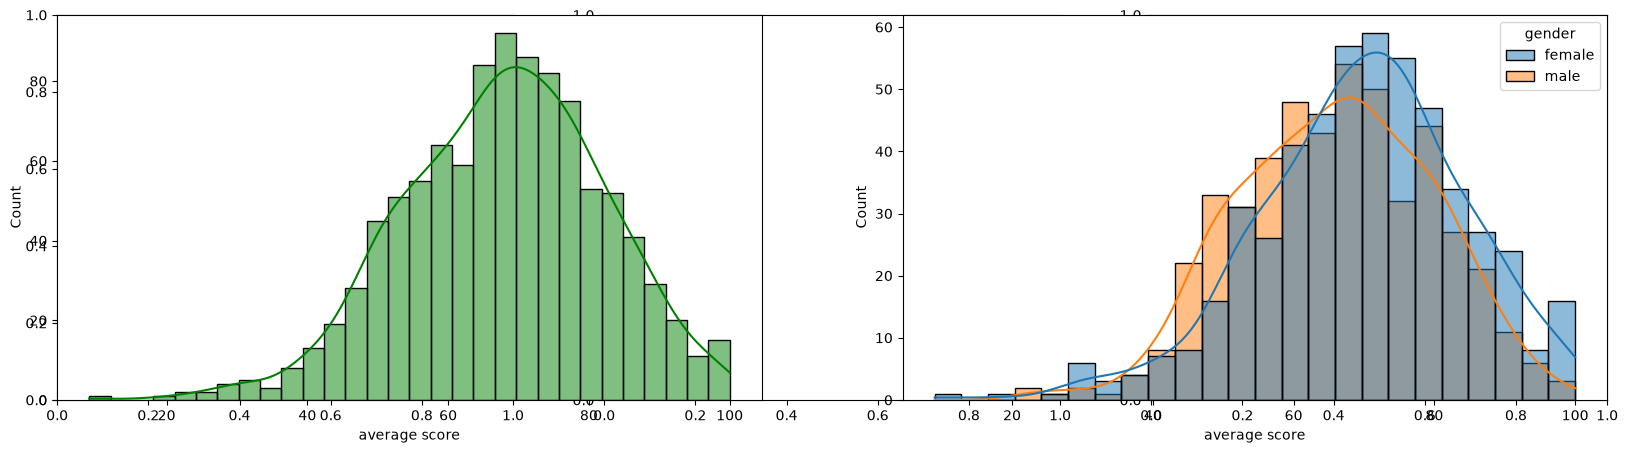

In [22]:
fig,axs=plt.subplots(1,3,figsize=(20,5) )
plt.subplot(121)
sns.histplot(data=df,x='average score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='average score',kde=True,hue='gender')
plt.show()

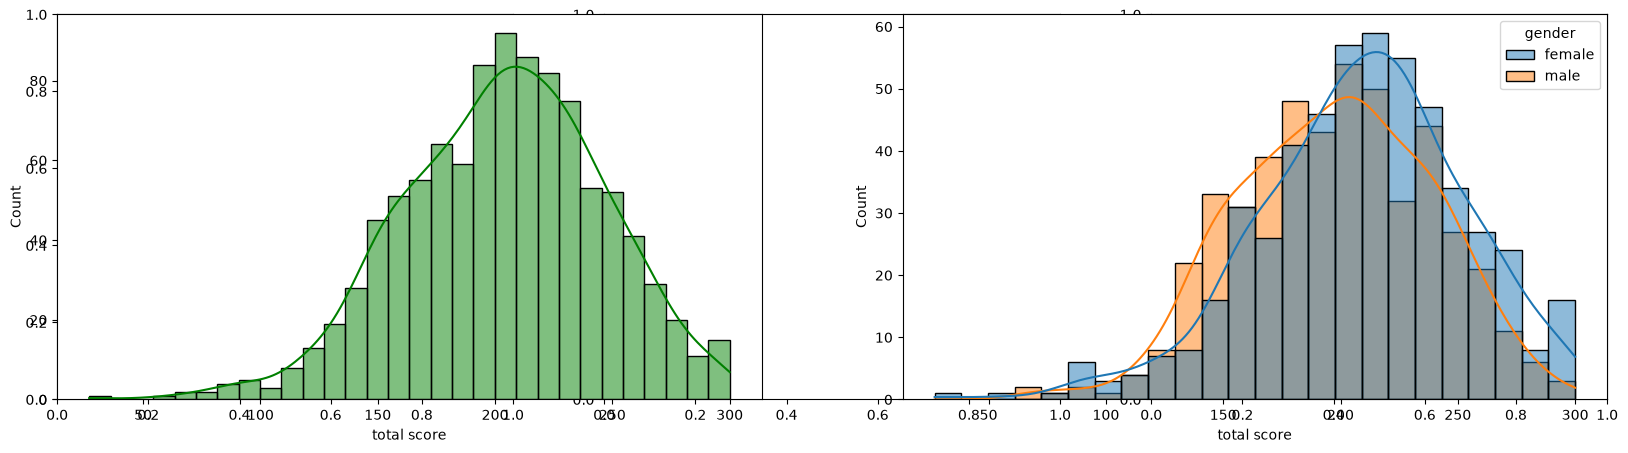

In [23]:
fig,axs=plt.subplots(1,3,figsize=(20,5) )
plt.subplot(121)
sns.histplot(data=df,x='total score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='total score',kde=True,hue='gender')
plt.show()